In [ ]:
# ----------------------------------------------
# BLOCK 1: Setup & Authentication
# ----------------------------------------------
import ee
from google.colab import drive
import geemap
import multiprocessing
from functools import partial
import glob
import os
import pandas as pd
import json
import re
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime, timedelta
import ast

ee.Authenticate()
drive.mount('/content/drive')
ee.Initialize(project="lake-ice")

Mounted at /content/drive


In [ ]:
# ----------------------------------------------
# BLOCK 2: Configuration
# ----------------------------------------------
# Configuration Classes
class CloudMaskingConfig:
    PROBABILITY_THRESHOLD = 50 # This is used for our probability-based mask, for individual pixel probability of being a cloud
    MAX_SCENE_CLOUDINESS = 75 # This is used to filter out entire images if they are too cloudy (not enough data to make it worthwhile)

class ClassificationConfig:
    ICE_THRESHOLD = 950
    SNOW_THRESHOLD = 3000

# Study metadata
STUDY_SITE_NAME = 'NS'
LAKE_ID_FIELD = 'id'

# Earth Engine asset -> MAKE SURE TO MANUALLY UPLOAD FROM YOUR MERGED S2 LAKE EXTENT SHAPEFILE IF PLD
LAKE_ASSET_PATH =f"projects/lake-ice/assets/ALPODlakes"#'projects/lake-ice/assets/{STUDY_SITE_NAME}_lakes_refined_merged'

# Years to process (each from April 1 to June 30 for YKD, May 15 to July 30 NS, )  MAKE EXTRA SURE TO CHANGE IN CODE BLOCK 6
YEARS = [2019,2020,2021,2022,2023,2024,2025]  # <-- Update this list as needed

# Output root directory
output_root_directory = f"/content/drive/My Drive/Data/50x50km {STUDY_SITE_NAME}"

In [ ]:
# ----------------------------------------------
# BLOCK 3: Get Target List of Lake IDs from Drive
# ----------------------------------------------


# For ALPOD usage:
# Path to the Excel file
lake_id_directory = f"/content/drive/My Drive/Data/50x50km {STUDY_SITE_NAME}/list_of_lakes_{STUDY_SITE_NAME.lower()}.xlsx"

# Read the Excel file
df = pd.read_excel(lake_id_directory)
selected_lake_ids = df['id'].dropna().tolist()
"""
# For PLD usage:
selected_lake_ids = numbers = [i for i in range(1106)]

print(selected_lake_ids)
print(len(selected_lake_ids))"""

'\n# For PLD usage:\nselected_lake_ids = numbers = [i for i in range(1106)]\n\nprint(selected_lake_ids)\nprint(len(selected_lake_ids))'

In [ ]:
# ----------------------------------------------
# BLOCK 4: Cloud Masking & Classification Logic
# ----------------------------------------------

def add_cloud_probability_to_sr_collection(sentinel2_surface_reflectance, start_date, end_date, area_of_interest):
    """Add cloud probability band to Sentinel-2 surface reflectance collection."""
    cloud_probability_collection = (ee.ImageCollection('COPERNICUS/S2_CLOUD_PROBABILITY')
                                   .filterBounds(area_of_interest)
                                   .filterDate(start_date, end_date))

    join = ee.Join.saveFirst('s2cloudless')
    filter = ee.Filter.equals(leftField='system:index', rightField='system:index')
    sr_with_cloud_prob = ee.ImageCollection(join.apply(sentinel2_surface_reflectance, cloud_probability_collection, filter))

    return sr_with_cloud_prob.map(lambda image: ee.Image(image).addBands(
        ee.Image(image.get('s2cloudless')).select('probability').rename('cloud_probability'))
    )

def mask_clouds_with_probability(image, cloud_probability_threshold=None):
    """Mask clouds using Scene Classification Layer (SCL) and cloud probability."""
    if cloud_probability_threshold is None:
        cloud_probability_threshold = CloudMaskingConfig.PROBABILITY_THRESHOLD

    # Use Scene Classification Layer (SCL) for cloud masking
    scl = image.select('SCL')

    # Create mask 1 to exclude problematic SCL values
    # Excludes: nodata, saturated/defective (0,1), cloud shadows (3), thin cirrus (10)
    scl_mask = scl.neq(3).And(scl.neq(10)).And(scl.neq(0)).And(scl.neq(1))

    # Create mask 2 to exclude clouds (since SCL cloud mask is not great)
    cloud_prob_mask = image.select('cloud_probability').lte(cloud_probability_threshold)

    # Combine masks
    combined_cloud_mask = scl_mask.And(cloud_prob_mask)

    return image.updateMask(combined_cloud_mask)

def classify_ice_snow_red_thresholding(image, ice_threshold=None, snow_threshold=None, cloud_probability_threshold=None):
    """Classify lake surface into water, ice, snow, or cloud categories using pixel values."""
    # Use default values from config if not provided
    if ice_threshold is None:
        ice_threshold = ClassificationConfig.ICE_THRESHOLD
    if snow_threshold is None:
        snow_threshold = ClassificationConfig.SNOW_THRESHOLD
    if cloud_probability_threshold is None:
        cloud_probability_threshold = CloudMaskingConfig.PROBABILITY_THRESHOLD

    # Use raw pixel values from B4 band (not scaled to reflectance)
    red_band = image.select('B4')  # Raw pixel values
    scl = image.select('SCL')
    cloud_prob = image.select('cloud_probability')

    # Define classification conditions using pixel thresholds
    conditions = {
        'snow': scl.eq(11).Or(red_band.gt(snow_threshold)),
        'ice': red_band.gt(ice_threshold).And(red_band.lte(snow_threshold)).And(scl.neq(11)),
        'water': red_band.lte(ice_threshold).Or(scl.eq(6))
    }

    # Apply classifications with priority order
    classified = (ee.Image(0)
              .where(conditions['water'], 3)
              .where(conditions['ice'], 1)
              .where(conditions['snow'], 2))

    return classified.toInt().rename('classified_lake_cover')

# def classify_ice_snow_neural_network(image, cloud_probability_threshold=None):

In [ ]:
# ----------------------------------------------
# BLOCK 5: Load Lakes from shapefile
# ----------------------------------------------
print("Loading lake feature collection...")
all_lakes = ee.FeatureCollection(LAKE_ASSET_PATH)

print("Filtering to selected lake IDs...")
lake_id_filter = ee.List(selected_lake_ids)
filtered_lake_collection = all_lakes.filter(ee.Filter.inList(LAKE_ID_FIELD, lake_id_filter))

print("Extracting geometries and lake IDs...")
lake_features = filtered_lake_collection.reduceColumns(
    ee.Reducer.toList(2),
    [LAKE_ID_FIELD, '.geo']
).get('list').getInfo()

print(f"Number of lakes to process: {len(lake_features)}")

Loading lake feature collection...
Filtering to selected lake IDs...
Extracting geometries and lake IDs...
Number of lakes to process: 5694


In [ ]:
# ----------------------------------------------
# BLOCK 6: Fast Processing Function for Single Lake Breakup
# ----------------------------------------------
def process_lake_fast(lake_data, year):
    index, lake_id, geometry = lake_data
    START_DATE = f"{year}-05-15"
    END_DATE = f"{year}-07-30"
    output_directory = os.path.join(output_root_directory, f"Time_Series_{year}")
    os.makedirs(output_directory, exist_ok=True)

    try:
        print(f"[{index}] Processing lake_id: {lake_id} for year {year}...")

        # Create geometry and feature
        geom = ee.Geometry(geometry)
        lake_feature = ee.Feature(geom).set(LAKE_ID_FIELD, lake_id)
        lake_fc = ee.FeatureCollection([lake_feature])

        # Load and filter Sentinel-2 data
        s2_sr = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
                 .filterDate(START_DATE, END_DATE)
                 .filterBounds(geom)
                 .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', CloudMaskingConfig.MAX_SCENE_CLOUDINESS)))

        # Add cloud probability and mask clouds
        s2 = (add_cloud_probability_to_sr_collection(s2_sr, START_DATE, END_DATE, geom)
              .map(mask_clouds_with_probability))

        # Annotate with date string
        s2 = s2.map(lambda img: img.set('date_str', ee.Date(img.date()).format('YYYY-MM-dd')))

        date_strings = ee.List(s2.aggregate_array('date_str')).distinct()

        def get_best_img_for_date(date_str):
            filtered = s2.filter(ee.Filter.eq('date_str', date_str))
            return filtered.sort('CLOUDY_PIXEL_PERCENTAGE').first()

        best_images = ee.ImageCollection.fromImages(date_strings.map(get_best_img_for_date))

        def add_metadata_and_classify(img):
            date = ee.Date(img.get('system:time_start')).format('YYYY-MM-dd')
            unix_time = ee.Number(img.date().millis())
            img_name = ee.String(img.get('system:index'))

            classified = classify_ice_snow_red_thresholding(img)

            meta_keys = [
                'CLOUDY_PIXEL_PERCENTAGE',
                'MEAN_SOLAR_AZIMUTH_ANGLE',
                'MEAN_SOLAR_ZENITH_ANGLE',
                'MEAN_VIEWING_AZIMUTH_ANGLE',
                'MEAN_VIEWING_ZENITH_ANGLE',
                'CLOUD_SHADOW_PERCENTAGE',
                'HIGH_PROBA_CLOUDS_PERCENTAGE',
                'MEDIUM_PROBA_CLOUDS_PERCENTAGE',
                'THIN_CIRRUS_PERCENTAGE'
            ]

            classified = classified.set({
                'date': date,
                'unix_time': unix_time,
                'image_name': img_name,
                'study_site': STUDY_SITE_NAME,
                'lake_id': lake_id,
                **{key: img.get(key) for key in meta_keys}
            })

            return classified

        classified_collection = best_images.map(add_metadata_and_classify)

        results = classified_collection.map(lambda img:
            img.select('classified_lake_cover').reduceRegions(
                collection=lake_fc,
                reducer=ee.Reducer.frequencyHistogram(),
                scale=10,
                crs='EPSG:4326'
            ).map(lambda f: f.set({
                'date': img.get('date'),
                'histogram': f.get('histogram'),
                'id': f.get('id'),
                'image_name': img.get('image_name'),
                'study_site': img.get('study_site'),
                'unix_time': img.get('unix_time'),
                **{key: img.get(key) for key in [
                    'CLOUDY_PIXEL_PERCENTAGE',
                    'CLOUD_SHADOW_PERCENTAGE',
                    'HIGH_PROBA_CLOUDS_PERCENTAGE',
                    'MEAN_SOLAR_AZIMUTH_ANGLE',
                    'MEAN_SOLAR_ZENITH_ANGLE',
                    'MEDIUM_PROBA_CLOUDS_PERCENTAGE',
                    'THIN_CIRRUS_PERCENTAGE'
                ]}
            }))
        ).flatten()

        results_info = results.getInfo()

        rows = []
        for feature in results_info['features']:
            props = feature['properties']
            props['.geo'] = json.dumps(feature['geometry'])
            rows.append(props)

        if rows:
            df = pd.DataFrame(rows)
            column_order = [
                'CLOUDY_PIXEL_PERCENTAGE', 'CLOUD_SHADOW_PERCENTAGE', 'HIGH_PROBA_CLOUDS_PERCENTAGE',
                'MEAN_SOLAR_AZIMUTH_ANGLE', 'MEAN_SOLAR_ZENITH_ANGLE', 'MEDIUM_PROBA_CLOUDS_PERCENTAGE',
                'THIN_CIRRUS_PERCENTAGE', 'date', 'histogram', 'id', 'image_name',
                'study_site', 'unix_time', '.geo'
            ]
            df = df.reindex(columns=column_order)
            output_path = os.path.join(output_directory, f'{lake_id}_ice_snow.csv')
            df.to_csv(output_path, index=False)
        else:
            print(f"[{index}] No results for lake_id: {lake_id}")
    except Exception as e:
        print(f"[{index}] Failed: {e}")
        import traceback
        traceback.print_exc()

# ----------------------------------------------
# Prepare Data for Processing
# ----------------------------------------------
def prepare_lake_data():
    return [(i, lake[0], lake[1]) for i, lake in enumerate(lake_features)]

# ----------------------------------------------
# Run Processing for All Years
# ----------------------------------------------
from functools import partial

for year in YEARS:
    print(f"\n=== Starting year {year} ===")
    lake_data_list = prepare_lake_data()
    process_fn = partial(process_lake_fast, year=year)

    with multiprocessing.Pool(processes=8) as pool:
        pool.map(process_fn, lake_data_list)

    print(f"Finished processing year {year}!")


=== Starting year 2019 ===
[356] Processing lake_id: 495189 for year 2019...[178] Processing lake_id: 496757 for year 2019...

[534] Processing lake_id: 502910 for year 2019...
[0] Processing lake_id: 493967 for year 2019...
[712] Processing lake_id: 496474 for year 2019...
[890] Processing lake_id: 494777 for year 2019...
[1068] Processing lake_id: 501676 for year 2019...
[1246] Processing lake_id: 489841 for year 2019...


[1069] Processing lake_id: 502442 for year 2019...
[1247] Processing lake_id: 489931 for year 2019...
[535] Processing lake_id: 502944 for year 2019...
[713] Processing lake_id: 496487 for year 2019...
[1] Processing lake_id: 493969 for year 2019...
[1070] Processing lake_id: 502484 for year 2019...
[179] Processing lake_id: 496767 for year 2019...
[891] Processing lake_id: 494787 for year 2019...
[1248] Processing lake_id: 490323 for year 2019...
[357] Processing lake_id: 495416 for year 2019...
[1071] Processing lake_id: 502796 for year 2019...
[180] Processing lake_id: 497005 for year 2019...
[536] Processing lake_id: 503121 for year 2019...
[714] Processing lake_id: 496495 for year 2019...
[2] Processing lake_id: 494002 for year 2019...
[892] Processing lake_id: 494961 for year 2019...
[1249] Processing lake_id: 490799 for year 2019...
[537] Processing lake_id: 503135 for year 2019...
[1072] Processing lake_id: 503068 for year 2019...
[358] Processing lake_id: 495535 for year 2019.

[12] Processing lake_id: 495713 for year 2019...
[907] Processing lake_id: 496579 for year 2019...
[727] Processing lake_id: 498711 for year 2019...
[1084] Processing lake_id: 490879 for year 2019...
[371] Processing lake_id: 497257 for year 2019...
[193] Processing lake_id: 497993 for year 2019...
[1085] Processing lake_id: 491290 for year 2019...
[908] Processing lake_id: 496629 for year 2019...
[1261] Processing lake_id: 497434 for year 2019...
[549] Processing lake_id: 503595 for year 2019...
[728] Processing lake_id: 498862 for year 2019...
[13] Processing lake_id: 495871 for year 2019...
[194] Processing lake_id: 498091 for year 2019...
[372] Processing lake_id: 497634 for year 2019...
[550] Processing lake_id: 488175 for year 2019...
[909] Processing lake_id: 496677 for year 2019...
[195] Processing lake_id: 498170 for year 2019...
[1262] Processing lake_id: 497787 for year 2019...
[373] Processing lake_id: 497771 for year 2019...
[729] Processing lake_id: 498998 for year 2019..

[196] Processing lake_id: 498178 for year 2019...
[374] Processing lake_id: 498352 for year 2019...
[730] Processing lake_id: 499192 for year 2019...
[1264] Processing lake_id: 499622 for year 2019...
[911] Processing lake_id: 497431 for year 2019...
[15] Processing lake_id: 496017 for year 2019...
[197] Processing lake_id: 498215 for year 2019...
[552] Processing lake_id: 488804 for year 2019...
[375] Processing lake_id: 498616 for year 2019...
[731] Processing lake_id: 499234 for year 2019...
[1265] Processing lake_id: 499861 for year 2019...
[1087] Processing lake_id: 491490 for year 2019...
[376] Processing lake_id: 498677 for year 2019...
[912] Processing lake_id: 497609 for year 2019...
[1266] Processing lake_id: 501715 for year 2019...
[553] Processing lake_id: 489194 for year 2019...
[198] Processing lake_id: 498285 for year 2019...
[732] Processing lake_id: 499382 for year 2019...


[16] Processing lake_id: 496353 for year 2019...
[913] Processing lake_id: 498447 for year 2019...
[1267] Processing lake_id: 502316 for year 2019...
[199] Processing lake_id: 498387 for year 2019...
[1088] Processing lake_id: 491502 for year 2019...
[733] Processing lake_id: 499767 for year 2019...
[554] Processing lake_id: 489462 for year 2019...
[1268] Processing lake_id: 502746 for year 2019...
[914] Processing lake_id: 498630 for year 2019...
[17] Processing lake_id: 496403 for year 2019...
[555] Processing lake_id: 489629 for year 2019...
[200] Processing lake_id: 498450 for year 2019...
[1089] Processing lake_id: 491642 for year 2019...
[734] Processing lake_id: 500109 for year 2019...
[377] Processing lake_id: 498899 for year 2019...
[915] Processing lake_id: 498668 for year 2019...
[556] Processing lake_id: 489699 for year 2019...
[18] Processing lake_id: 496470 for year 2019...
[1269] Processing lake_id: 502999 for year 2019...
[1090] Processing lake_id: 492006 for year 2019.

[936] Processing lake_id: 497059 for year 2019...
[221] Processing lake_id: 499940 for year 2019...
[578] Processing lake_id: 491162 for year 2019...
[399] Processing lake_id: 496115 for year 2019...
[756] Processing lake_id: 497675 for year 2019...
[1289] Processing lake_id: 501628 for year 2019...
[1112] Processing lake_id: 498596 for year 2019...
[222] Processing lake_id: 499970 for year 2019...
[579] Processing lake_id: 491252 for year 2019...
[400] Processing lake_id: 496256 for year 2019...
[937] Processing lake_id: 497147 for year 2019...
[757] Processing lake_id: 497712 for year 2019...
[35] Processing lake_id: 498793 for year 2019...
[1290] Processing lake_id: 502707 for year 2019...
[401] Processing lake_id: 496273 for year 2019...
[1113] Processing lake_id: 498760 for year 2019...
[223] Processing lake_id: 500037 for year 2019...
[938] Processing lake_id: 497206 for year 2019...
[402] Processing lake_id: 496311 for year 2019...
[580] Processing lake_id: 491366 for year 2019.

... (246 outputs left out)

[1068] Processing lake_id: 501676 for year 2025...


[1246] Processing lake_id: 489841 for year 2025...


[1069] Processing lake_id: 502442 for year 2025...
[1247] Processing lake_id: 489931 for year 2025...
[357] Processing lake_id: 495416 for year 2025...
[179] Processing lake_id: 496767 for year 2025...
[1] Processing lake_id: 493969 for year 2025...
[535] Processing lake_id: 502944 for year 2025...
[713] Processing lake_id: 496487 for year 2025...
[1070] Processing lake_id: 502484 for year 2025...
[891] Processing lake_id: 494787 for year 2025...
[180] Processing lake_id: 497005 for year 2025...
[1071] Processing lake_id: 502796 for year 2025...
[536] Processing lake_id: 503121 for year 2025...
[358] Processing lake_id: 495535 for year 2025...
[1248] Processing lake_id: 490323 for year 2025...
[2] Processing lake_id: 494002 for year 2025...
[714] Processing lake_id: 496495 for year 2025...
[892] Processing lake_id: 494961 for year 2025...
[1072] Processing lake_id: 503068 for year 2025...
[537] Processing lake_id: 503135 for year 2025...
[1249] Processing lake_id: 490799 for year 2025.

[736] Processing lake_id: 500469 for year 2025...
[201] Processing lake_id: 498618 for year 2025...
[915] Processing lake_id: 498668 for year 2025...
[1269] Processing lake_id: 502999 for year 2025...
[383] Processing lake_id: 493927 for year 2025...
[559] Processing lake_id: 490025 for year 2025...
[737] Processing lake_id: 501347 for year 2025...
[202] Processing lake_id: 498655 for year 2025...
[203] Processing lake_id: 498821 for year 2025...
[18] Processing lake_id: 496470 for year 2025...
[916] Processing lake_id: 498945 for year 2025...
[1094] Processing lake_id: 492717 for year 2025...
[560] Processing lake_id: 490146 for year 2025...
[1270] Processing lake_id: 489907 for year 2025...
[1095] Processing lake_id: 492938 for year 2025...
[738] Processing lake_id: 502349 for year 2025...
[384] Processing lake_id: 494499 for year 2025...
[1271] Processing lake_id: 491089 for year 2025...
[204] Processing lake_id: 498832 for year 2025...
[917] Processing lake_id: 498946 for year 2025

In [ ]:
# ----------------------------------------------
# BLOCK 7: Google Colab-Optimized Serial Processing for Time Series CSVs
# ----------------------------------------------

import os
import glob
import ast
import pandas as pd
import numpy as np
from tqdm import tqdm
import shutil

# --- Configuration ---
base_dir = f"/content/drive/My Drive/Data/50x50km {STUDY_SITE_NAME}"
study_site = STUDY_SITE_NAME
output_dir = f"{base_dir}"
cloud_threshold = 33 # For how much of the INDIVIDUAL LAKE is cloud covered
os.makedirs(output_dir, exist_ok=True)

# --- Functions ---

def parse_histogram(hist_str):
    try:
        hist_dict = ast.literal_eval(hist_str)
        return {int(k): float(v) for k, v in hist_dict.items()}
    except:
        return {}

def process_csv_with_validity(df, cloud_threshold=75):
    processed_data = []

    for _, row in df.iterrows():
        hist = parse_histogram(row['histogram'])
        cloud = hist.get(0, 0)
        ice = hist.get(1, 0)
        snow = hist.get(2, 0)
        water = hist.get(3, 0)

        total = cloud + ice + snow + water
        if total == 0:
            continue

        cloud_pct = (cloud / total) * 100
        is_valid = cloud_pct <= cloud_threshold

        if is_valid:
            valid_total = ice + snow + water
            if valid_total == 0:
                continue
            water_pct = (water / valid_total) * 100
        else:
            valid_total = ice + snow + water
            water_pct = (water / valid_total) * 100 if valid_total > 0 else 0

        processed_data.append({
            'date': pd.to_datetime(row['date']),
            'water_pct': water_pct,
            'cloud_pct': cloud_pct,
            'valid': is_valid,
            'ice': ice,
            'snow': snow,
            'water': water,
            'cloud': cloud
        })

    if not processed_data:
        return None

    result_df = pd.DataFrame(processed_data)

    agg_dict = {
        'ice': 'sum',
        'snow': 'sum',
        'water': 'sum',
        'cloud': 'sum',
        'valid': 'all'
    }

    daily_df = result_df.groupby('date').agg(agg_dict).reset_index()
    daily_df['total'] = daily_df['ice'] + daily_df['snow'] + daily_df['water'] + daily_df['cloud']
    daily_df['cloud_pct'] = (daily_df['cloud'] / daily_df['total']) * 100
    daily_df['valid'] = daily_df['cloud_pct'] <= cloud_threshold

    valid_mask = daily_df['valid']
    daily_df['total_valid'] = daily_df['ice'] + daily_df['snow'] + daily_df['water']
    daily_df.loc[valid_mask, 'water_pct'] = (daily_df.loc[valid_mask, 'water'] / daily_df.loc[valid_mask, 'total_valid']) * 100
    daily_df.loc[~valid_mask, 'water_pct'] = np.nan

    return daily_df.sort_values('date')

def find_breakup_date_valid_only(daily_df):
    if daily_df is None or len(daily_df) < 2:
        return None, None, None

    valid_df = daily_df[daily_df['valid']].copy()
    if len(valid_df) < 2:
        return None, None, None

    valid_df = valid_df.sort_values('date')
    dates = valid_df['date'].values
    water_pct = valid_df['water_pct'].values

    if water_pct.max() < 75:
        return None, None, None

    for i in range(len(water_pct) - 1):
        if water_pct[i] < 75 and water_pct[i + 1] >= 75:
            x1, y1 = dates[i], water_pct[i]
            x2, y2 = dates[i + 1], water_pct[i + 1]

            x1_num = pd.to_datetime(x1).value
            x2_num = pd.to_datetime(x2).value
            crossing_num = x1_num + (x2_num - x1_num) * (75 - y1) / (y2 - y1)
            crossing_date = pd.to_datetime(crossing_num)

            error_days_negative = (crossing_date - pd.to_datetime(x1)).days
            error_days_positive = (pd.to_datetime(x2) - crossing_date).days

            return crossing_date, error_days_negative, error_days_positive

    return None, None, None

def process_csv_file(csv_path, cloud_threshold):
    try:
        df = pd.read_csv(csv_path, usecols=['date', 'histogram'])
        if 'histogram' not in df.columns or df['histogram'].isnull().all():
            return None

        processed_df = process_csv_with_validity(df, cloud_threshold)
        if processed_df is None or processed_df.empty:
            return None

        total_observations = len(processed_df)
        valid_observations = len(processed_df[processed_df['valid']])
        breakup_date, err_neg, err_pos = find_breakup_date_valid_only(processed_df)

        if breakup_date is not None:
            lake_id = os.path.basename(csv_path).split("_")[0]
            return {
                'lake_id': lake_id,
                'breakup_date': breakup_date,
                'error_days_negative': err_neg,
                'error_days_positive': err_pos,
                'total_observations': total_observations,
                'valid_observations': valid_observations,
                'cloud_threshold_used': cloud_threshold
            }
    except Exception as e:
        print(f"Failed on {csv_path}: {e}")
        return None

# --- Main Execution ---

year_folders = sorted(glob.glob(f"{base_dir}/Time_Series_*"))

for folder in year_folders:
    year_str = os.path.basename(folder).split("_")[-1]
    if not year_str.isdigit():
        continue
    year = int(year_str)
    print(f"\n Processing year: {year}")

    out_path = os.path.join(output_dir, f"breakup_{year}_stats_{study_site}.csv")
    if os.path.exists(out_path):
        print(f"⏭Output already exists for year {year}, skipping...")
        continue

    csv_files = glob.glob(f"{folder}/*_ice_snow.csv")
    if not csv_files:
        print(f"No CSVs found for year {year}, skipping...")
        continue

    # Copy files to /tmp to speed up I/O
    local_tmp = f"/tmp/time_series_{year}"
    os.makedirs(local_tmp, exist_ok=True)

    print("Copying files to local /tmp ...")
    for src_file in tqdm(csv_files, desc="Copying"):
        dst_file = os.path.join(local_tmp, os.path.basename(src_file))
        shutil.copyfile(src_file, dst_file)

    local_csv_files = glob.glob(f"{local_tmp}/*_ice_snow.csv")

    results = []
    print("Processing files ...")
    for csv_path in tqdm(local_csv_files, desc=f"Year {year}"):
        result = process_csv_file(csv_path, cloud_threshold=cloud_threshold)
        if result is not None:
            results.append(result)

    if results:
        year_df = pd.DataFrame(results)
        year_df.to_csv(out_path, index=False)
        print(f"Saved: {out_path} with {len(results)} lakes")
    else:
        print(f"No valid breakup data for year {year}")

print("\n All processing complete!")


In [ ]:
# ----------------------------------------------
# BLOCK 8: Graph yearly breakup histograms
# ----------------------------------------------

import glob
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd
import numpy as np
import os

# --------------------
# Configuration
# --------------------
date_bin_width = 1
start_month_day = ("04-15", "06-30")  # shared plotting window -> change per study site
study_site = STUDY_SITE_NAME
excluded_years = []
dummy_year = 2000  # used for aligning all dates on the same x-axis

# --------------------
# Load and filter data
# --------------------
csv_files = sorted(glob.glob(f"{output_root_directory}/breakup_*_stats_{study_site}.csv"))
print(study_site)
breakup_dfs = []

for csv_path in csv_files:
    try:
        year = int(os.path.basename(csv_path).split('_')[1])
        if year in excluded_years:
            continue
        df = pd.read_csv(csv_path)
        df['breakup_date'] = pd.to_datetime(df['breakup_date'], errors='coerce')
        valid_df = df[df['breakup_date'].notna()].copy()

        if not valid_df.empty:
            breakup_dfs.append((year, valid_df))
    except Exception as e:
        print(f"Skipping {csv_path}: {e}")

if not breakup_dfs:
    raise ValueError("No valid breakup data found after exclusions.")

# --------------------
# Custom tick locator for 10th, 20th, 30th of each month
# --------------------
def create_custom_ticks(start_date, end_date, days=[10, 20, 30]):
    """Create custom tick marks for specific days of each month"""
    ticks = []
    current_date = start_date.replace(day=1)

    while current_date <= end_date:
        for day in days:
            try:
                tick_date = current_date.replace(day=day)
                if start_date <= tick_date <= end_date:
                    ticks.append(tick_date)
            except ValueError:
                # Day doesn't exist in this month (e.g., Feb 30th)
                pass

        # Move to next month
        if current_date.month == 12:
            current_date = current_date.replace(year=current_date.year + 1, month=1)
        else:
            current_date = current_date.replace(month=current_date.month + 1)

    return ticks

# --------------------
# Shared date range (dummy year)
# --------------------
plot_start_date = pd.to_datetime(f"{dummy_year}-{start_month_day[0]}")
plot_end_date = pd.to_datetime(f"{dummy_year}-{start_month_day[1]}")
shared_date_range = pd.date_range(start=plot_start_date, end=plot_end_date, freq=f'{date_bin_width}D')

# Create custom tick locations
custom_ticks = create_custom_ticks(plot_start_date.to_pydatetime(), plot_end_date.to_pydatetime(), [10, 20, 30])


# --------------------
# Plotting Setup
# --------------------
n_years = len(breakup_dfs)
fig = plt.figure(figsize=(12, 1.0 * n_years))
gs = fig.add_gridspec(n_years, 2, width_ratios=[1, 2], height_ratios=[1] * n_years,
                      wspace=0.3, hspace=0.15)
cmap = plt.get_cmap("GnBu")
colors = cmap(np.linspace(0.2, 1, n_years))

# --------------------
# Left: Histogram of actual breakup dates
# --------------------
for i, (year, df) in enumerate(breakup_dfs):
    ax = fig.add_subplot(gs[i, 0])
    color = colors[i]

    # Convert actual breakup dates to dummy year
    shifted_dates = df['breakup_date'].apply(lambda d: d.replace(year=dummy_year))
    mask = (shifted_dates >= plot_start_date) & (shifted_dates <= plot_end_date)
    filtered_dates = shifted_dates[mask]

    # Histogram
    bins = pd.date_range(start=plot_start_date, end=plot_end_date + pd.Timedelta(days=1), freq=f'{date_bin_width}D')
    counts, edges = np.histogram(filtered_dates, bins=bins)
    bin_centers = edges[:-1] + np.diff(edges) / 2

    ax.plot(bin_centers, counts, color=color, linewidth=2)
    ax.fill_between(bin_centers, counts, color=color, alpha=0.4)

    lake_count = len(df)
    ax.text(1.01, 0.0, f"{year}\n(n={lake_count})", transform=ax.transAxes,
            va='bottom', ha='left', fontsize=9, color=color)

    ax.set_xlim(plot_start_date, plot_end_date)
    ax.set_ylim(0, max(counts.max(), 1) * 1.2)

    ax.spines[['top', 'right', 'left']].set_visible(False)
    ax.get_yaxis().set_visible(False)
    ax.grid(True, alpha=0.2, axis='x')
    ax.set_xticks(custom_ticks)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b-%d'))

    if i == n_years - 1:
        ax.set_xlabel("Ice-Out Date", fontsize=9)
        plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, fontsize=8)
    else:
        ax.tick_params(labelbottom=False)

    if i == 0:
        ax.set_ylabel("Number of Lakes", fontsize=10, labelpad=45)

# --------------------
# Right: Cumulative % Ice-Free using actual breakup dates
# --------------------
ax_right = fig.add_subplot(gs[:, 1])
ax_right.set_ylabel('% of Lakes Ice-Free', fontsize=10)
ax_right.set_xlabel("Ice-Out Date", fontsize=9)
ax_right.set_ylim(-2, 102)
ax_right.set_xlim(plot_start_date, plot_end_date)
ax_right.grid(True, alpha=0.2, axis='y')
ax_right.spines[['top', 'right', 'left']].set_visible(False)
ax_right.spines['bottom'].set_linewidth(0.2)
ax_right.yaxis.set_major_locator(plt.MultipleLocator(10))
ax_right.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{int(y)}%'))
ax_right.set_xticks(custom_ticks)
ax_right.xaxis.set_major_formatter(mdates.DateFormatter('%b-%d'))
plt.setp(ax_right.xaxis.get_majorticklabels(), rotation=45, fontsize=8)

for i, (year, df) in enumerate(breakup_dfs):
    color = colors[i]
    shifted_dates = df['breakup_date'].apply(lambda d: d.replace(year=dummy_year)).sort_values()
    cumulative = np.arange(1, len(shifted_dates) + 1) / len(shifted_dates) * 100
    ax_right.plot(shifted_dates.values, cumulative, color=color, linewidth=2.5, label=str(year))

# Legend
ax_right.legend(loc='upper left', fontsize=9, frameon=True, fancybox=True,
                bbox_to_anchor=(0.02, 0.97), title="Year", title_fontsize=10)

# Adjust layout and y-label
plt.subplots_adjust(top=0.96, bottom=0.06, left=0.06, right=0.98)
fig.text(0.03, 0.5, "Number of Lakes", va='center', ha='center',
         rotation='vertical', fontsize=10)

plt.show()

In [ ]:
# ----------------------------------------------
# BLOCK 9: Graph yearly breakup histograms with error bands
# ----------------------------------------------

import glob
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd
import numpy as np
import os

# --------------------
# Configuration
# --------------------
date_bin_width = 1
start_month_day = ("04-15", "06-30")  # shared plotting window -> change per study site
study_site = STUDY_SITE_NAME
excluded_years = []
dummy_year = 2000  # used for aligning all dates on the same x-axis

# --------------------
# Load and filter data
# --------------------
csv_files = sorted(glob.glob(f"{output_root_directory}/breakup_*_stats_{study_site}.csv"))
print(study_site)
breakup_dfs = []

for csv_path in csv_files:
    try:
        year = int(os.path.basename(csv_path).split('_')[1])
        if year in excluded_years:
            continue
        df = pd.read_csv(csv_path)
        df['breakup_date'] = pd.to_datetime(df['breakup_date'], errors='coerce')

        # Ensure error columns exist
        if 'error_days_negative' not in df.columns:
            df['error_days_negative'] = 0
        if 'error_days_positive' not in df.columns:
            df['error_days_positive'] = 0

        valid_df = df[df['breakup_date'].notna()].copy()

        if not valid_df.empty:
            breakup_dfs.append((year, valid_df))
    except Exception as e:
        print(f"Skipping {csv_path}: {e}")

if not breakup_dfs:
    raise ValueError("No valid breakup data found after exclusions.")

# --------------------
# Custom tick locator for 10th, 20th, 30th of each month
# --------------------
def create_custom_ticks(start_date, end_date, days=[10, 20, 30]):
    """Create custom tick marks for specific days of each month"""
    ticks = []
    current_date = start_date.replace(day=1)

    while current_date <= end_date:
        for day in days:
            try:
                tick_date = current_date.replace(day=day)
                if start_date <= tick_date <= end_date:
                    ticks.append(tick_date)
            except ValueError:
                # Day doesn't exist in this month (e.g., Feb 30th)
                pass

        # Move to next month
        if current_date.month == 12:
            current_date = current_date.replace(year=current_date.year + 1, month=1)
        else:
            current_date = current_date.replace(month=current_date.month + 1)

    return ticks

# --------------------
# Shared date range (dummy year)
# --------------------
plot_start_date = pd.to_datetime(f"{dummy_year}-{start_month_day[0]}")
plot_end_date = pd.to_datetime(f"{dummy_year}-{start_month_day[1]}")

# Create custom tick locations
custom_ticks = create_custom_ticks(plot_start_date.to_pydatetime(), plot_end_date.to_pydatetime(), [10, 20, 30])

# --------------------
# Plotting Setup (horizontal layout)
# --------------------
n_years = len(breakup_dfs)
fig, axes = plt.subplots(1, n_years, figsize=(3 * n_years, 3), sharey=True)  # 1 row, n_years columns
if n_years == 1:
    axes = [axes]  # Ensure axes is always a list

cmap = plt.get_cmap("YlOrRd")
colors = cmap(np.linspace(0.2, 1, n_years))

# --------------------
# Individual plots for each year (side-by-side)
# --------------------
for i, (year, df) in enumerate(breakup_dfs):
    ax = axes[i]
    color = colors[i]

    shifted_dates = df['breakup_date'].apply(lambda d: d.replace(year=dummy_year))
    mask = (shifted_dates >= plot_start_date) & (shifted_dates <= plot_end_date)
    filtered_df = df[mask].copy()
    filtered_dates = shifted_dates[mask]

    if len(filtered_dates) == 0:
        continue

    sorted_indices = filtered_dates.argsort()
    sorted_dates = filtered_dates.iloc[sorted_indices]
    sorted_df = filtered_df.iloc[sorted_indices]

    cumulative = np.arange(1, len(sorted_dates) + 1) / len(sorted_dates) * 100

    error_left, error_right = [], []
    for date, row in zip(sorted_dates, sorted_df.itertuples()):
        error_left.append(date - pd.Timedelta(days=row.error_days_negative))
        error_right.append(date + pd.Timedelta(days=row.error_days_positive))

    ax.fill_betweenx(cumulative, error_left, error_right, color=color, alpha=0.35, linewidth=0)
    ax.plot(sorted_dates.values, cumulative, color=color, linewidth=2.5,
            label=f'{year} (n={len(sorted_dates)})')

    # Formatting
    ax.set_title(str(year), fontsize=10)
    ax.set_ylim(-2, 102)
    ax.set_xlim(plot_start_date, plot_end_date)
    ax.grid(True, alpha=0.2, axis='both')
    ax.spines[['top', 'right']].set_visible(False)
    ax.yaxis.set_major_locator(plt.MultipleLocator(25))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{int(y)}%'))

    if i > 0:
        ax.tick_params(labelleft=False)
    else:
        ax.set_ylabel("% Ice-Free", fontsize=10)

    ax.set_xticks(custom_ticks)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b-%d'))
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, fontsize=8)

# Main title
fig.suptitle(f'Ice-Out Progression by Year - {study_site}', fontsize=14, y=0.98)

plt.tight_layout()
plt.show()


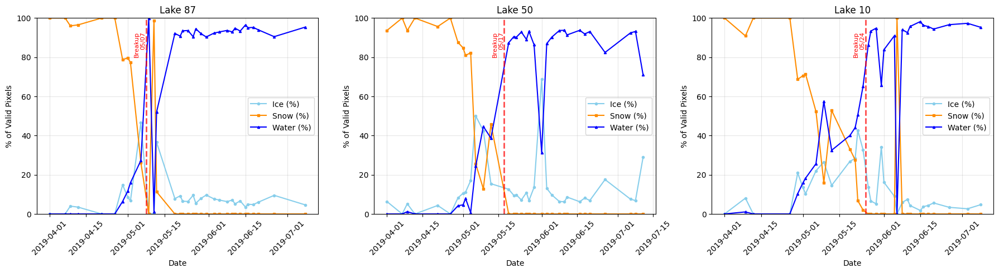

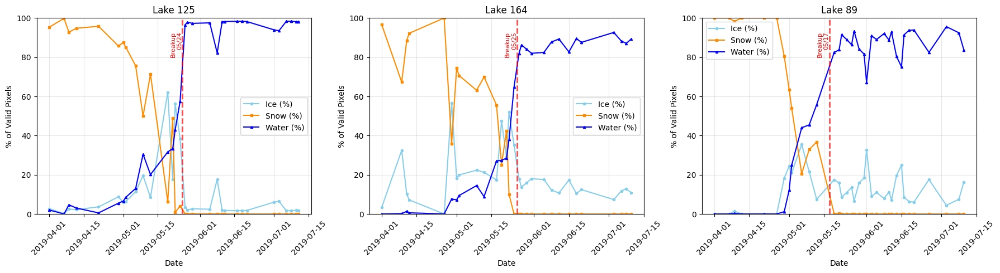

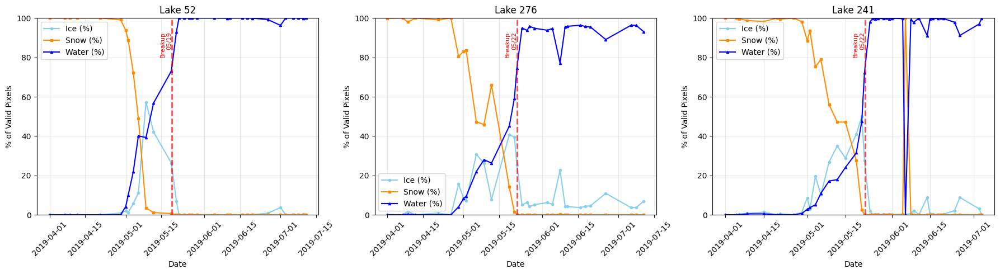

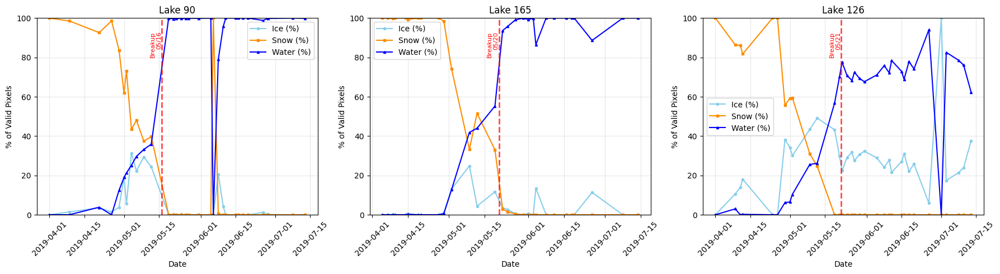

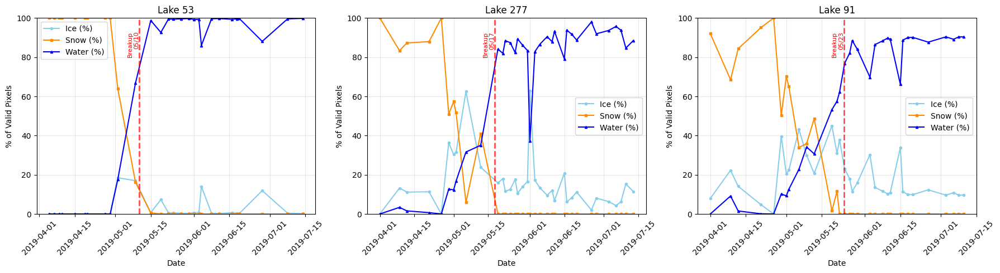

...

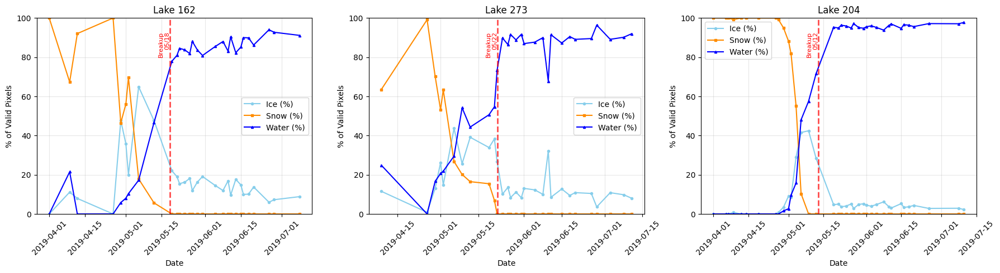

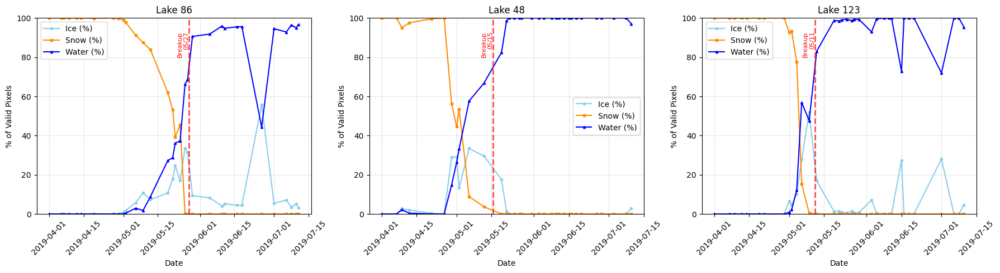

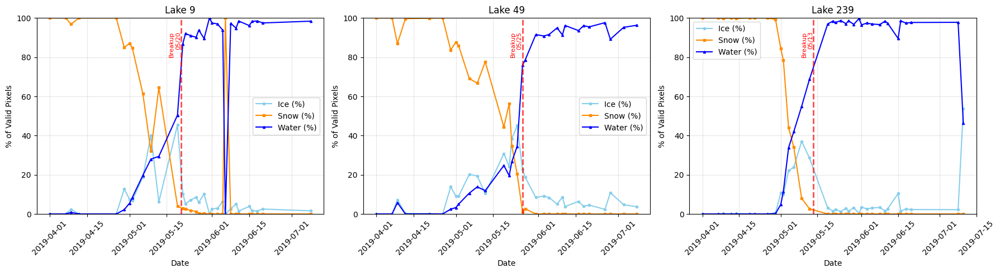

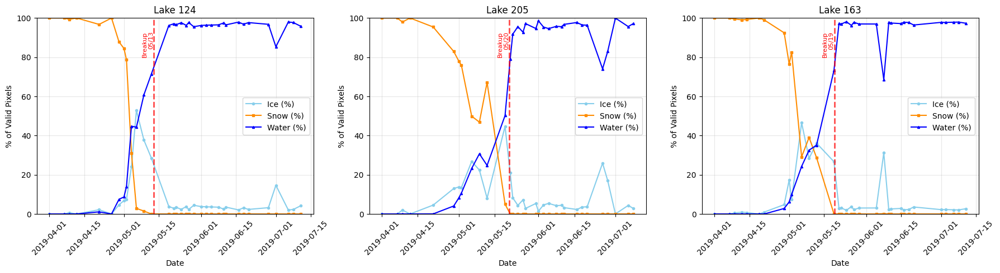

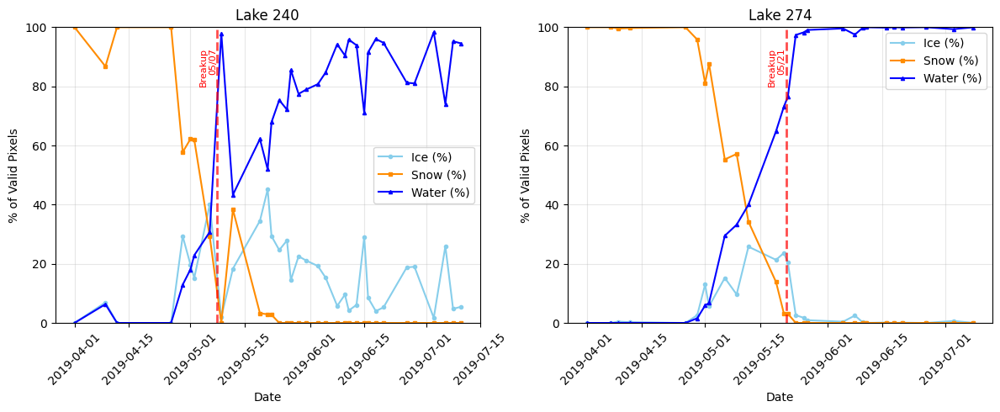

In [ ]:
# ----------------------------------------------
# BLOCK 10: Graph individual time series for a given year
# ----------------------------------------------
import ast

def find_breakup_date(daily_df):
    if len(daily_df) < 2:
        return None, None, None
    daily_df = daily_df.sort_values('date')
    dates = daily_df['date'].values
    water_pct = daily_df['water_pct'].values
    if water_pct.max() < 75:
        return None, None, None
    for i in range(len(water_pct) - 1):
        if water_pct[i] < 75 and water_pct[i + 1] >= 75:
            x1, y1 = dates[i], water_pct[i]
            x2, y2 = dates[i + 1], water_pct[i + 1]
            x1_num = pd.to_datetime(x1).value
            x2_num = pd.to_datetime(x2).value
            crossing_num = x1_num + (x2_num - x1_num) * (75 - y1) / (y2 - y1)
            crossing_date = pd.to_datetime(crossing_num)
            error_days_negative = (crossing_date - pd.to_datetime(x1)).days
            error_days_positive = (pd.to_datetime(x2) - crossing_date).days
            return crossing_date, error_days_negative, error_days_positive
    return None, None, None

def parse_histogram(hist_str):
    try:
        hist_dict = ast.literal_eval(hist_str)
        return {int(k): float(v) for k, v in hist_dict.items()}
    except:
        return {}

def process_csv(filepath, cloud_threshold=75):
    df = pd.read_csv(filepath)
    if df.empty:
        return None

    ice_vals, snow_vals, water_vals, cloud_vals = [], [], [], []
    dates = []

    for _, row in df.iterrows():
        hist = parse_histogram(row['histogram'])
        cloud = hist.get(0, 0)
        ice = hist.get(1, 0)
        snow = hist.get(2, 0)
        water = hist.get(3, 0)
        total = cloud + ice + snow + water
        if total == 0:
            continue
        cloud_pct = (cloud / total) * 100
        if cloud_pct > cloud_threshold:
            continue
        valid_total = ice + snow + water
        if valid_total == 0:
            continue
        ice_vals.append(ice)
        snow_vals.append(snow)
        water_vals.append(water)
        cloud_vals.append(cloud)
        dates.append(pd.to_datetime(row['date']))

    if not dates:
        return None

    daily_df = pd.DataFrame({
        'date': dates,
        'ice': ice_vals,
        'snow': snow_vals,
        'water': water_vals,
        'cloud': cloud_vals
    })

    daily_df = daily_df.groupby('date').sum().reset_index()
    daily_df['total_valid'] = daily_df['ice'] + daily_df['snow'] + daily_df['water']
    daily_df = daily_df[daily_df['total_valid'] > 0].copy()
    daily_df['ice_pct'] = (daily_df['ice'] / daily_df['total_valid']) * 100
    daily_df['snow_pct'] = (daily_df['snow'] / daily_df['total_valid']) * 100
    daily_df['water_pct'] = (daily_df['water'] / daily_df['total_valid']) * 100
    daily_df = daily_df.sort_values('date')
    return daily_df

def visualize_lake_time_series(output_root_directory, year, cloud_threshold=75):
    folder_path = f"{output_root_directory}/Time_Series_{year}/"
    files = [f for f in os.listdir(folder_path) if f.endswith('_ice_snow.csv')]

    cols = 3
    for i in range(0, len(files), cols):
        subset = files[i:i+cols]
        fig, axes = plt.subplots(1, len(subset), figsize=(6 * len(subset), 5), squeeze=False)
        axes = axes[0]

        for ax, filename in zip(axes, subset):
            lake_id = filename.split('_')[0]
            full_path = os.path.join(folder_path, filename)
            daily_df = process_csv(full_path, cloud_threshold)

            if daily_df is None or daily_df.empty:
                ax.set_title(f"Lake {lake_id}\nNo valid data")
                ax.text(0.5, 0.5, 'No valid data after cloud filtering',
                        ha='center', va='center', transform=ax.transAxes)
                continue

            breakup_date, _, _ = find_breakup_date(daily_df)

            ax.plot(daily_df['date'], daily_df['ice_pct'], label='Ice (%)', color='#87CEEB', marker='o', markersize=3)
            ax.plot(daily_df['date'], daily_df['snow_pct'], label='Snow (%)', color='#FF8C00', marker='s', markersize=3)
            ax.plot(daily_df['date'], daily_df['water_pct'], label='Water (%)', color='#0000FF', marker='^', markersize=3)

            if breakup_date is not None:
                ax.axvline(breakup_date, color='red', linestyle='--', alpha=0.7, linewidth=2)
                ax.text(breakup_date, 80, f'Breakup\n{breakup_date.strftime("%m/%d")}',
                        rotation=90, ha='right', va='bottom', color='red', fontsize=8)

            ax.set_title(f"Lake {lake_id}")
            ax.set_xlabel('Date')
            ax.set_ylabel('% of Valid Pixels')
            ax.set_ylim(0, 100)
            ax.grid(True, alpha=0.3)
            ax.legend()
            ax.tick_params(axis='x', rotation=45)

        plt.tight_layout()
        plt.show()

visualize_lake_time_series(output_root_directory, 2019, cloud_threshold=33)